<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/06_sobel_and_prewitt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sobel and Prewitt operators

An edge is a place where the brightness changes quickly, so edges can be found by estimating the
image gradient. The Sobel and Prewitt operators do this with two small 3 x 3 kernels, one for
each direction:

| | $G_x$ (change from left to right) | $G_y$ (change from top to bottom) |
|---|---|---|
| Prewitt | $\begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix}$ | $\begin{bmatrix} -1 & -1 & -1 \\ 0 & 0 & 0 \\ 1 & 1 & 1 \end{bmatrix}$ |
| Sobel | $\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$ | $\begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$ |

Sobel gives the middle row or column twice the weight, which smooths a little and makes it less
sensitive to noise. The edge strength is the gradient magnitude $\sqrt{G_x^2 + G_y^2}$.

$G_x$ responds to **vertical** edges (brightness changing as you move sideways) and $G_y$ responds
to **horizontal** edges. The first version of this notebook had these two labels swapped.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

In [2]:
image = data.camera()

prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])
prewitt_y = prewitt_x.T
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.T

## Applying a kernel

To apply a 3 x 3 kernel, every pixel is replaced by the weighted sum of its 3 x 3 neighbourhood.
Instead of looping over pixels, the function below loops over the 9 kernel positions and adds a
shifted copy of the whole image each time. The border is padded by reflecting the image, which is
what OpenCV does by default.

In [3]:
def apply_kernel(img, kernel):
    padded = np.pad(img.astype(float), 1, mode="reflect")
    h, w = img.shape
    out = np.zeros((h, w))
    for di in range(3):
        for dj in range(3):
            out += kernel[di, dj] * padded[di:di + h, dj:dj + w]
    return out


def gradient(img, kx, ky):
    gx = apply_kernel(img, kx)
    gy = apply_kernel(img, ky)
    return gx, gy, np.hypot(gx, gy)

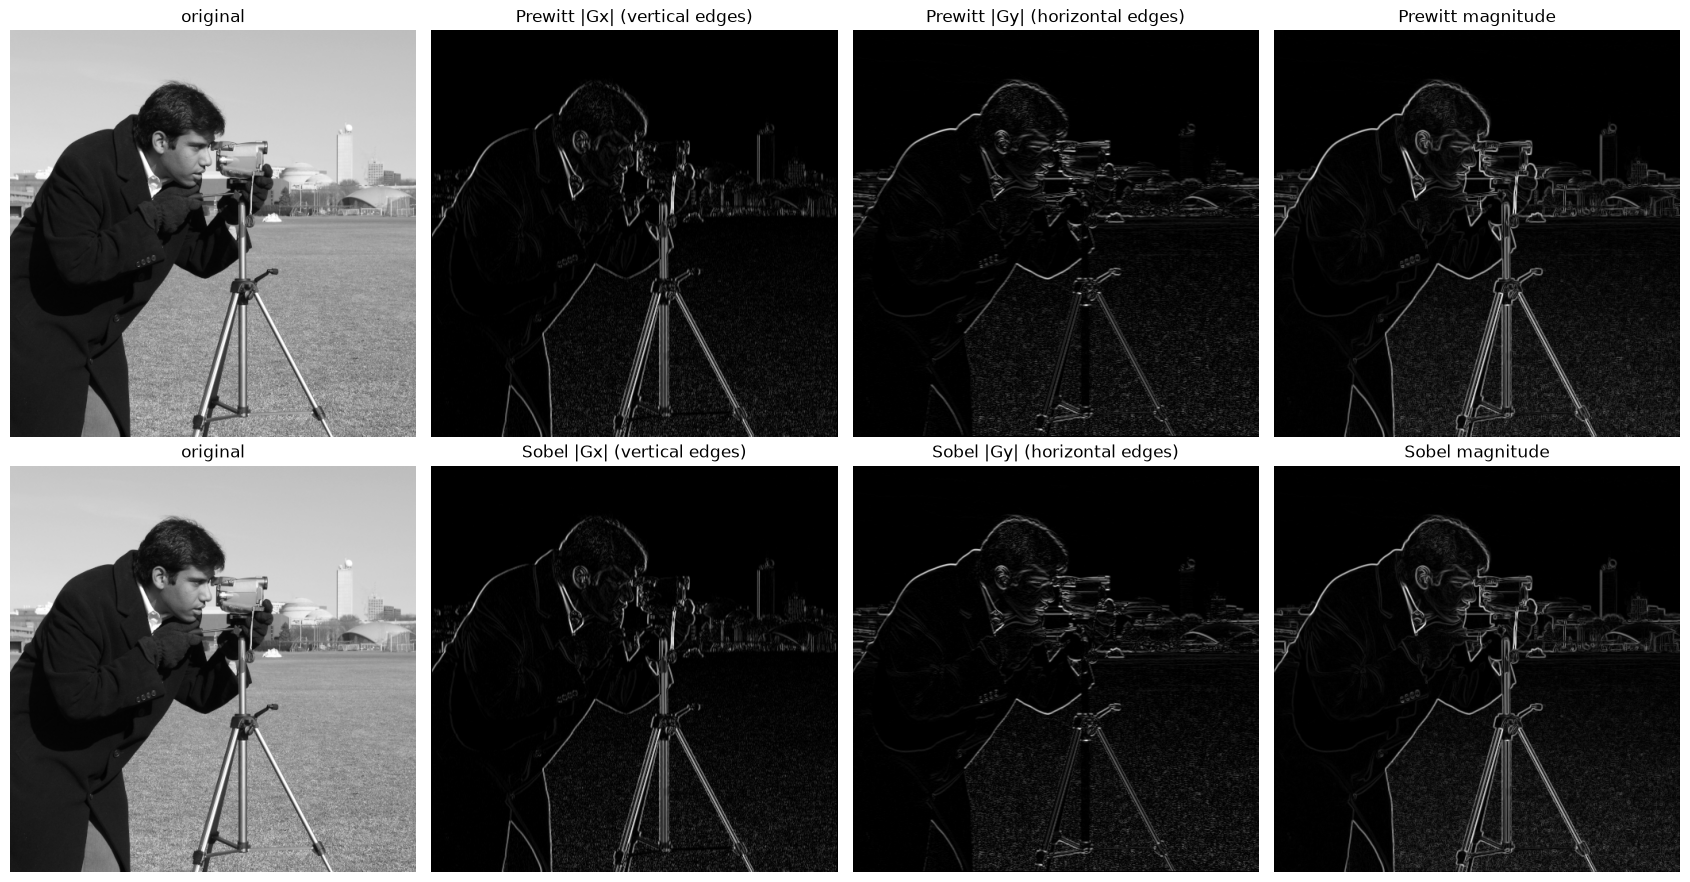

In [4]:
results = {
    "Prewitt": gradient(image, prewitt_x, prewitt_y),
    "Sobel": gradient(image, sobel_x, sobel_y),
}


def show(img):
    # scale to 0..255 for display instead of clipping, so strong edges do not saturate
    return img / img.max() * 255


fig, ax = plt.subplots(2, 4, figsize=(17, 9))
for row, (name, (gx, gy, mag)) in enumerate(results.items()):
    ax[row, 0].imshow(image); ax[row, 0].set_title("original")
    ax[row, 1].imshow(show(np.abs(gx))); ax[row, 1].set_title(f"{name} |Gx| (vertical edges)")
    ax[row, 2].imshow(show(np.abs(gy))); ax[row, 2].set_title(f"{name} |Gy| (horizontal edges)")
    ax[row, 3].imshow(show(mag)); ax[row, 3].set_title(f"{name} magnitude")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

Look at the tripod legs: they are nearly vertical, so they show up clearly in $|G_x|$ and are much
weaker in $|G_y|$. The horizon and the tops of the buildings are the opposite.

The negative values of $G_x$ and $G_y$ are just as important as the positive ones (a dark-to-bright
edge versus bright-to-dark), so the absolute value is shown. Clipping to 0..255 would throw half
of the edges away.

## Comparison with OpenCV

`cv2.Sobel` with `ksize=3` uses exactly the Sobel kernels above.

In [5]:
gx, gy, mag = results["Sobel"]
print("Gx same as cv2.Sobel:", np.allclose(gx, cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)))
print("Gy same as cv2.Sobel:", np.allclose(gy, cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)))
print("Prewitt Gx same as cv2.filter2D:",
      np.allclose(results["Prewitt"][0], cv2.filter2D(image, cv2.CV_64F, prewitt_x.astype(float))))

Gx same as cv2.Sobel: True
Gy same as cv2.Sobel: True
Prewitt Gx same as cv2.filter2D: True
